# Validação do dataset: lotação da academia do campus

Este notebook verifica se o dataset serve para prever a próxima observação de lotação com uma LSTM. Ele audita os dados, prepara a série, mede referências simples e faz um primeiro treino para testar o pipeline de ponta a ponta.

O conjunto de teste fica reservado para a etapa final: nenhum modelo é avaliado nele aqui.

## 1. Configuração

O notebook roda no Google Colab sem configuração adicional. Todas as bibliotecas usadas já vêm instaladas no ambiente do Colab, e o dataset é público, então o download não exige credenciais do Kaggle. Para garantir que todos analisem os mesmos dados, o arquivo é conferido pelo hash SHA-256.

In [1]:
import copy
import hashlib
import io
import random
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import acf
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

DATASET_URL = "https://www.kaggle.com/api/v1/datasets/download/nsrose7224/crowdedness-at-the-campus-gym"
DATASET_SHA256 = "490412204d0d90c58036788adaaba1a16968dfab525fad3fefe78a18bc998ff4"
LOCAL_DATASET_PATHS = [Path("data/raw/data.csv"), Path("../data/raw/data.csv")]

FILL_LIMIT_HOURS = 8
WINDOW_LENGTHS = [24, 168]
SEEDS = [7, 21, 42]
HIDDEN_UNITS = 64
LEARNING_RATE = 1e-3
BATCH_SIZE = 64
MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5

BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
MUTED_INK = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": SECONDARY_INK,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.7,
    "xtick.color": MUTED_INK,
    "ytick.color": MUTED_INK,
    "text.color": SECONDARY_INK,
    "legend.frameon": False,
    "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
def read_verified_dataset():
    for path in LOCAL_DATASET_PATHS:
        if path.is_file() and hashlib.sha256(path.read_bytes()).hexdigest() == DATASET_SHA256:
            return pd.read_csv(path)
    request = urllib.request.Request(DATASET_URL, headers={"User-Agent": "dataset-ingest"})
    with urllib.request.urlopen(request, timeout=120) as response:
        archive_content = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_content)) as archive:
        csv_content = archive.read("data.csv")
    if hashlib.sha256(csv_content).hexdigest() != DATASET_SHA256:
        raise ValueError("O arquivo baixado difere da versão validada do dataset")
    output_path = LOCAL_DATASET_PATHS[0]
    output_path.parent.mkdir(parents=True, exist_ok=True)
    output_path.write_bytes(csv_content)
    return pd.read_csv(io.BytesIO(csv_content))


raw = read_verified_dataset()
print(f"{raw.shape[0]} linhas e {raw.shape[1]} colunas")
raw.head()

62184 linhas e 11 colunas


,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


## 2. Problema e dataset

| Item | Descrição |
|---|---|
| **Dataset** | Crowdedness at the Campus Gym |
| **Fonte** | [Kaggle, publicado por nsrose7224](https://www.kaggle.com/datasets/nsrose7224/crowdedness-at-the-campus-gym) |
| **Problema** | Prever quantas pessoas estarão na academia na próxima observação, para que os alunos escolham melhores horários e a gestão planeje a operação |
| **Variável-alvo** | `number_people`, número de pessoas presentes |
| **Frequência** | Leituras registradas a cada 10 minutos, aproximadamente, e analisadas na seção 3 |
| **Variáveis de apoio** | Calendário, feriados, início e período de semestre, e temperatura em graus Fahrenheit |

**Por que este dataset:** a lotação depende do histórico recente e de ciclos humanos, como a rotina do dia e da semana. Esse é o tipo de dependência temporal que uma LSTM pode aprender. A série também cobre mais de um ano e meio, o que permite separar treino, validação e teste em ordem cronológica.

In [3]:
local_clock = pd.to_datetime(raw["date"].str[:19])
column_overview = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "valores_distintos": raw.nunique(),
    "mínimo": raw.min(numeric_only=True),
    "máximo": raw.max(numeric_only=True),
})
calendar_agreement = {
    "hour": float((raw["hour"] == local_clock.dt.hour).mean()),
    "day_of_week": float((raw["day_of_week"] == local_clock.dt.day_of_week).mean()),
    "month": float((raw["month"] == local_clock.dt.month).mean()),
}
print(f"Período: {local_clock.min()} a {local_clock.max()}")
print(f"Linhas duplicadas: {raw.duplicated().sum()}")
print(f"Concordância das colunas de calendário com a data: {calendar_agreement}")
column_overview

Período: 2015-08-14 17:00:11 a 2017-03-18 19:22:51


Linhas duplicadas: 0
Concordância das colunas de calendário com a data: {'hour': 1.0, 'day_of_week': 1.0, 'month': 1.0}


,tipo,nulos,valores_distintos,mínimo,máximo
date,str,0,62184,NaN,NaN
day_of_week,int64,0,7,0.00,6.00
hour,int64,0,24,0.00,23.00
is_during_semester,int64,0,2,0.00,1.00
is_holiday,int64,0,2,0.00,1.00
is_start_of_semester,int64,0,2,0.00,1.00
is_weekend,int64,0,2,0.00,1.00
month,int64,0,12,1.00,12.00
number_people,int64,0,128,0.00,145.00
temperature,float64,0,2599,38.14,87.17


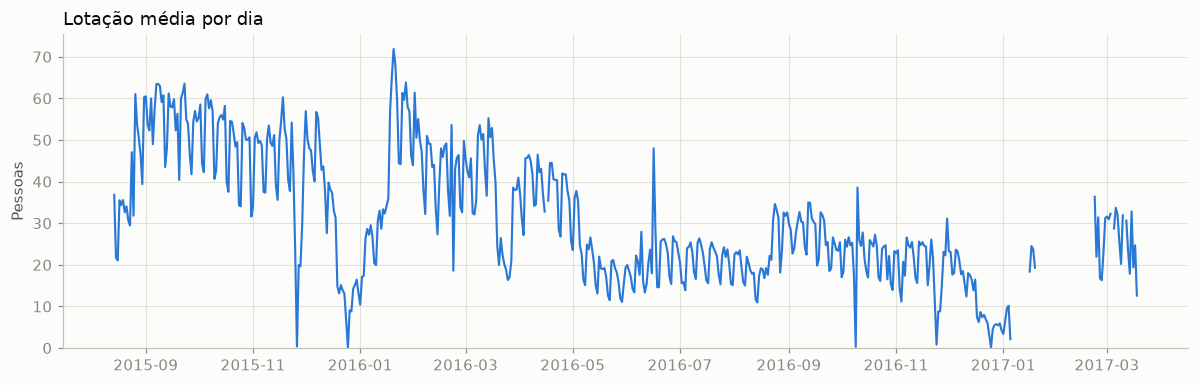

In [4]:
daily_mean = raw.assign(local_clock=local_clock).set_index("local_clock").sort_index()["number_people"].resample("D").mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily_mean.index, daily_mean.values, color=BLUE, linewidth=1.4)
ax.set_title("Lotação média por dia")
ax.set_ylabel("Pessoas")
ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

## 3. Limpeza e preparação

### 3.1 Resolvendo a ordem cronológica das leituras

In [5]:
instants = pd.to_datetime(raw["date"], utc=True)
steps_back_in_time = instants.diff().dt.total_seconds() < 0

print(f"Leituras em ordem crescente: {instants.is_monotonic_increasing}")
print(f"Linhas com data anterior à da linha de cima: {steps_back_in_time.sum()}")
raw.loc[steps_back_in_time, ["date", "number_people"]].head()

Leituras em ordem crescente: False
Linhas com data anterior à da linha de cima: 1


,date,number_people
51178,2016-11-06 01:01:52-08:00,0


In [6]:
readings = (
    raw.assign(instant_utc=instants, local_time=local_clock)
    .sort_values("instant_utc")
    .reset_index(drop=True)
)

print(f"Leituras em ordem crescente após a ordenação: {readings['instant_utc'].is_monotonic_increasing}")

Leituras em ordem crescente após a ordenação: True


### 3.2 Resolvendo a amostragem irregular

In [7]:
interval_minutes = readings["instant_utc"].diff().dt.total_seconds().div(60).dropna()
interval_groups = pd.cut(
    interval_minutes,
    bins=[0, 15, 30, 60, 180, 720, np.inf],
    labels=["até 15 min", "15 a 30 min", "30 a 60 min", "1 a 3 h", "3 a 12 h", "acima de 12 h"],
)
interval_table = interval_groups.value_counts(sort=False).rename("intervalos").rename_axis("duração").to_frame()
interval_table["parcela_%"] = 100 * interval_table["intervalos"] / len(interval_minutes)

grid_rows = []
for rule in ["10min", "30min", "1h"]:
    grid = readings.set_index("local_time")["number_people"].resample(rule).mean()
    grid_rows.append({"grade": rule, "posições": len(grid), "posições_vazias_%": 100 * grid.isna().mean()})

print(f"Intervalo mediano entre leituras: {interval_minutes.median():.1f} min")
display(interval_table)
display(pd.DataFrame(grid_rows))

Intervalo mediano entre leituras: 10.0 min

,intervalos,parcela_%
duração,,
até 15 min,56756,91.27
15 a 30 min,4932,7.93
30 a 60 min,119,0.19
1 a 3 h,68,0.11
3 a 12 h,295,0.47
acima de 12 h,13,0.02


,grade,posições,posições_vazias_%
0,10min,83823,26.28
1,30min,27941,18.22
2,1h,13971,16.71


In [8]:
hourly = (
    readings.set_index("local_time")["number_people"]
    .resample("1h")
    .mean()
    .rename("people_observed")
    .to_frame()
)
hourly.index.name = "hour"

print(f"Grade horária: {len(hourly)} horas, de {hourly.index.min()} a {hourly.index.max()}")
print(f"Horas com pelo menos uma leitura: {hourly['people_observed'].notna().sum()}")
hourly.head()

Grade horária: 13971 horas, de 2015-08-14 17:00:00 a 2017-03-18 19:00:00
Horas com pelo menos uma leitura: 11637


,people_observed
hour,
2015-08-14 17:00:00,42.20
2015-08-14 18:00:00,47.80
2015-08-14 19:00:00,39.80
2015-08-14 20:00:00,40.20
2015-08-14 21:00:00,44.80


### 3.3 Resolvendo as lacunas noturnas de coleta

Lacunas acima de 3h: 308
Duração mediana: 4.3h | percentil 90: 7.4h


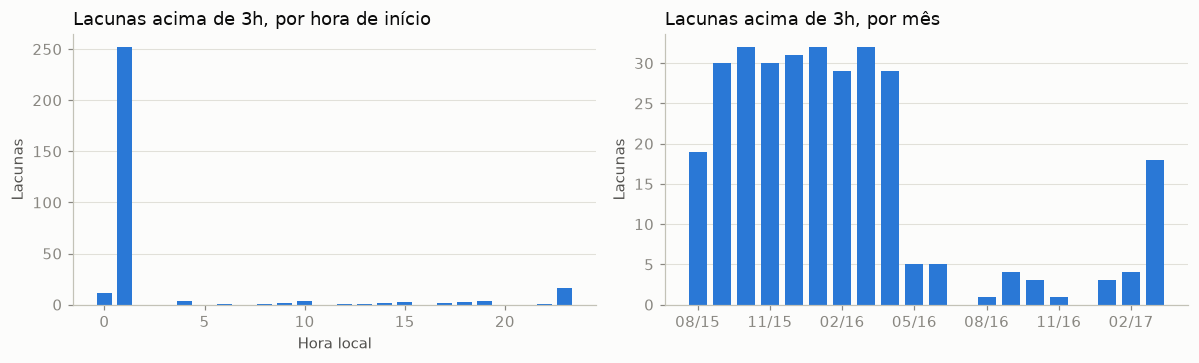

In [9]:
gap_hours = readings["instant_utc"].diff().dt.total_seconds().div(3600)
long_gaps = readings.assign(gap_hours=gap_hours, gap_start=readings["local_time"].shift(1)).query("gap_hours > 3")

gaps_by_start_hour = long_gaps["gap_start"].dt.hour.value_counts().reindex(range(24), fill_value=0)
all_months = pd.period_range(readings["local_time"].min(), readings["local_time"].max(), freq="M")
gaps_by_month = long_gaps.groupby(long_gaps["local_time"].dt.to_period("M")).size().reindex(all_months, fill_value=0)

print(f"Lacunas acima de 3h: {len(long_gaps)}")
print(f"Duração mediana: {long_gaps['gap_hours'].median():.1f}h | percentil 90: {long_gaps['gap_hours'].quantile(0.9):.1f}h")

fig, (hour_axis, month_axis) = plt.subplots(1, 2, figsize=(11, 3.4))
hour_axis.bar(gaps_by_start_hour.index, gaps_by_start_hour.values, color=BLUE, width=0.75)
hour_axis.set_title("Lacunas acima de 3h, por hora de início")
hour_axis.set_xlabel("Hora local")
hour_axis.set_ylabel("Lacunas")
hour_axis.grid(axis="x", visible=False)
month_positions = np.arange(len(gaps_by_month))
month_axis.bar(month_positions, gaps_by_month.values, color=BLUE, width=0.75)
month_axis.set_title("Lacunas acima de 3h, por mês")
month_axis.set_xticks(month_positions[::3], [month.strftime("%m/%y") for month in gaps_by_month.index[::3]])
month_axis.set_ylabel("Lacunas")
month_axis.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

In [10]:
def missing_run_lengths(series):
    is_missing = series.isna()
    run_id = (is_missing != is_missing.shift()).cumsum()
    return is_missing.groupby(run_id).transform("sum").where(is_missing, 0).astype(int)


def complete_window_targets(observed, available, window):
    has_complete_window = available.astype(float).rolling(window).sum().shift(1).eq(window)
    return observed.notna() & has_complete_window


hourly["missing_run_hours"] = missing_run_lengths(hourly["people_observed"])

sensitivity_rows = []
for fill_limit in [0, 3, 6, 8, 12]:
    is_filled = hourly["missing_run_hours"].between(1, fill_limit)
    available = hourly["people_observed"].notna() | is_filled
    targets_by_window = {
        window: complete_window_targets(hourly["people_observed"], available, window)
        for window in WINDOW_LENGTHS
    }
    sensitivity_rows.append({
        "limite_horas": fill_limit,
        "horas_preenchidas_%": 100 * is_filled.sum() / available.sum(),
        "alvos_janela_24h": int(targets_by_window[24].sum()),
        "alvos_janela_168h": int(targets_by_window[168].sum()),
        "alvos_comuns": int((targets_by_window[24] & targets_by_window[168]).sum()),
    })

hourly["is_imputed"] = hourly["missing_run_hours"].between(1, FILL_LIMIT_HOURS).astype(int)
hourly["is_available"] = hourly["people_observed"].notna() | hourly["is_imputed"].eq(1)

print(f"Lacunas acima de 3h cobertas pelo limite de {FILL_LIMIT_HOURS}h: {100 * long_gaps['gap_hours'].le(FILL_LIMIT_HOURS).mean():.1f}%")
pd.DataFrame(sensitivity_rows)

Lacunas acima de 3h cobertas pelo limite de 8h: 91.9%


,limite_horas,horas_preenchidas_%,alvos_janela_24h,alvos_janela_168h,alvos_comuns
0,0,0.00,5432,3852,3852
1,3,6.43,10784,7638,7638
2,6,7.42,11209,9484,9484
3,8,8.03,11369,9969,9969
4,12,8.40,11453,10445,10445


### 3.4 Resolvendo leakage causado pela interpolação linear

In [11]:
def linear_fill(observed):
    return observed.interpolate(method="time", limit_area="inside")


def compare_inputs_after_changing_target(fill_function, target_hour, lookback_hours=4, people_added=50):
    changed_observed = hourly["people_observed"].copy()
    changed_observed.loc[target_hour] += people_added
    first_input = target_hour - pd.Timedelta(hours=lookback_hours)
    last_input = target_hour - pd.Timedelta(hours=1)
    comparison = pd.DataFrame({
        "entrada_original": fill_function(hourly["people_observed"]).loc[first_input:last_input],
        "entrada_com_alvo_alterado": fill_function(changed_observed).loc[first_input:last_input],
        "hora_preenchida": hourly["is_imputed"].loc[first_input:last_input],
    })
    comparison["diferença"] = comparison["entrada_com_alvo_alterado"] - comparison["entrada_original"]
    return comparison


follows_imputed_hour = hourly["is_imputed"].shift(1).eq(1)
targets_after_imputed_hour = hourly.index[hourly["people_observed"].notna() & follows_imputed_hour]
example_target_hour = targets_after_imputed_hour[0]

print(f"Alvo do exemplo: {example_target_hour}, somando 50 pessoas ao valor real")
print(f"Alvos logo depois de uma hora preenchida: {len(targets_after_imputed_hour)}")
compare_inputs_after_changing_target(linear_fill, example_target_hour)

Alvo do exemplo: 2015-08-15 05:00:00, somando 50 pessoas ao valor real
Alvos logo depois de uma hora preenchida: 322


,entrada_original,entrada_com_alvo_alterado,hora_preenchida,diferença
hour,,,,
2015-08-15 01:00:00,0.00,0.00,0,0.00
2015-08-15 02:00:00,0.12,12.62,1,12.50
2015-08-15 03:00:00,0.25,25.25,1,25.00
2015-08-15 04:00:00,0.38,37.88,1,37.50


In [12]:
def causal_fill(observed):
    return observed.ffill().where(hourly["is_available"])


comparison_after_fix = compare_inputs_after_changing_target(causal_fill, example_target_hour)
assert comparison_after_fix["diferença"].abs().sum() == 0

hourly["people"] = causal_fill(hourly["people_observed"])

print(f"Horas preenchidas com o último valor observado: {hourly['is_imputed'].sum()}")
comparison_after_fix

Horas preenchidas com o último valor observado: 1016


,entrada_original,entrada_com_alvo_alterado,hora_preenchida,diferença
hour,,,,
2015-08-15 01:00:00,0.00,0.00,0,0.00
2015-08-15 02:00:00,0.00,0.00,1,0.00
2015-08-15 03:00:00,0.00,0.00,1,0.00
2015-08-15 04:00:00,0.00,0.00,1,0.00


### 3.5 Resolvendo as lacunas longas do fim da série

In [13]:
is_empty = hourly["people"].isna()
empty_run_id = (is_empty != is_empty.shift()).cumsum()[is_empty]
empty_runs = (
    pd.Series(hourly.index[is_empty], index=empty_run_id.values)
    .groupby(level=0)
    .agg(["min", "max", "size"])
    .rename(columns={"min": "início", "max": "fim", "size": "horas"})
    .sort_values("horas", ascending=False)
    .reset_index(drop=True)
)
empty_runs["dias"] = empty_runs["horas"] / 24

blocked_rows = []
for window in WINDOW_LENGTHS:
    window_touches_gap = is_empty.astype(float).rolling(window, min_periods=1).sum().shift(1).gt(0)
    blocked_rows.append({
        "janela_horas": window,
        "alvos_observados": int(hourly["people_observed"].notna().sum()),
        "alvos_com_lacuna_na_janela": int((hourly["people_observed"].notna() & window_touches_gap).sum()),
    })

print(f"Lacunas acima de {FILL_LIMIT_HOURS}h: {len(empty_runs)}")
display(empty_runs.head(8))
display(pd.DataFrame(blocked_rows))

Lacunas acima de 8h: 16


,início,fim,horas,dias
0,2017-01-20 00:00:00,2017-02-13 22:00:00,599,24.96
1,2017-01-06 00:00:00,2017-01-16 20:00:00,261,10.88
2,2017-02-14 00:00:00,2017-02-22 12:00:00,205,8.54
3,2016-04-15 15:00:00,2016-04-17 09:00:00,43,1.79
4,2017-03-11 00:00:00,2017-03-12 16:00:00,41,1.71
5,2017-03-04 00:00:00,2017-03-05 09:00:00,34,1.42
6,2016-06-16 01:00:00,2016-06-16 21:00:00,21,0.88
7,2015-09-18 19:00:00,2015-09-19 12:00:00,18,0.75


,janela_horas,alvos_observados,alvos_com_lacuna_na_janela
0,24,11637,247
1,168,11637,1522


In [14]:
eligible_by_window = {
    window: complete_window_targets(hourly["people_observed"], hourly["people"].notna(), window)
    for window in WINDOW_LENGTHS
}
common_targets = eligible_by_window[24] & eligible_by_window[168]
target_hours = hourly.index[common_targets]

print(f"Alvos com janela completa de 24h: {eligible_by_window[24].sum()}")
print(f"Alvos com janela completa de 168h: {eligible_by_window[168].sum()}")
print(f"Datas-alvo comuns às duas janelas: {len(target_hours)}")
print(f"Primeira e última data-alvo: {target_hours.min()} e {target_hours.max()}")

Alvos com janela completa de 24h: 11369
Alvos com janela completa de 168h: 9969
Datas-alvo comuns às duas janelas: 9969
Primeira e última data-alvo: 2015-08-21 17:00:00 e 2017-03-03 23:00:00


### 3.6 Resolvendo o teste reduzido pelo corte por calendário

In [15]:
total_hours = len(hourly)
calendar_slices = {
    "treino": hourly.iloc[: int(total_hours * 0.6)],
    "validação": hourly.iloc[int(total_hours * 0.6) : int(total_hours * 0.8)],
    "teste": hourly.iloc[int(total_hours * 0.8) :],
}
total_observed = hourly["people_observed"].notna().sum()
pd.DataFrame([
    {
        "partição": name,
        "início": part.index.min(),
        "fim": part.index.max(),
        "parcela_do_calendário_%": 100 * len(part) / total_hours,
        "horas_vazias_%": 100 * part["people_observed"].isna().mean(),
        "parcela_das_observações_%": 100 * part["people_observed"].notna().sum() / total_observed,
    }
    for name, part in calendar_slices.items()
])

,partição,início,fim,parcela_do_calendário_%,horas_vazias_%,parcela_das_observações_%
0,treino,2015-08-14 17:00:00,2016-07-28 22:00:00,60.00,11.52,63.73
1,validação,2016-07-28 23:00:00,2016-11-22 08:00:00,20.00,2.54,23.40
2,teste,2016-11-22 09:00:00,2017-03-18 19:00:00,20.01,46.40,12.87


In [16]:
target_count = len(target_hours)
train_size = int(target_count * 0.6)
validation_size = int(target_count * 0.8) - train_size
partitions = {
    "treino": target_hours[:train_size],
    "validação": target_hours[train_size : train_size + validation_size],
    "teste": target_hours[train_size + validation_size :],
}
assert len(partitions["teste"]) / target_count >= 0.2

pd.DataFrame([
    {
        "partição": name,
        "início": dates.min(),
        "fim": dates.max(),
        "datas_alvo": len(dates),
        "parcela_das_datas_alvo_%": 100 * len(dates) / target_count,
    }
    for name, dates in partitions.items()
])

,partição,início,fim,datas_alvo,parcela_das_datas_alvo_%
0,treino,2015-08-21 17:00:00,2016-06-30 12:00:00,5981,60.00
1,validação,2016-06-30 13:00:00,2016-09-30 00:00:00,1994,20.00
2,teste,2016-09-30 01:00:00,2017-03-03 23:00:00,1994,20.00


## 4. Comportamento da série

Os padrões de ciclo são analisados só no período de treino. A comparação de nível entre as partições é a única informação usada do período de teste.

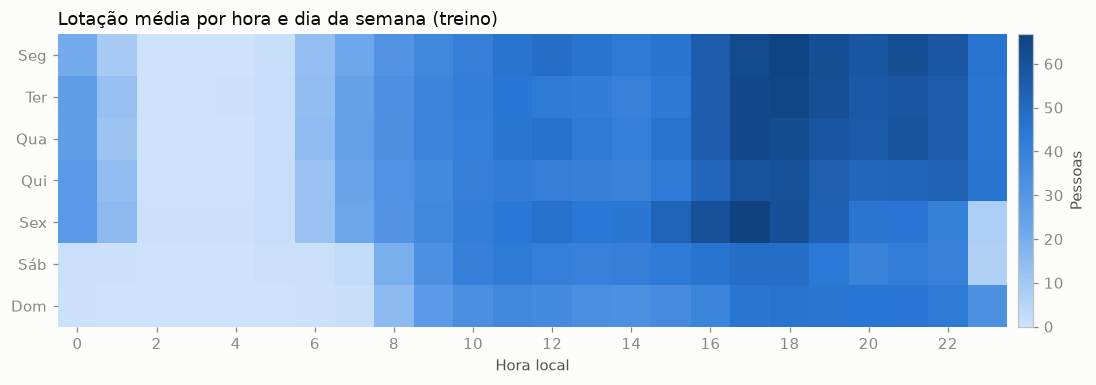

In [17]:
training_end = partitions["treino"].max()
training_hourly = hourly.loc[:training_end]
training_readings = readings[readings["local_time"] <= training_end]

weekday_names = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
hour_weekday_mean = (
    training_hourly.assign(hour_of_day=training_hourly.index.hour, weekday=training_hourly.index.day_of_week)
    .pivot_table(index="weekday", columns="hour_of_day", values="people_observed", aggfunc="mean")
)
sequential_blues = LinearSegmentedColormap.from_list("sequential_blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#104281"])

fig, ax = plt.subplots(figsize=(11, 3.6))
heatmap = ax.imshow(hour_weekday_mean.values, aspect="auto", cmap=sequential_blues, vmin=0)
ax.set_title("Lotação média por hora e dia da semana (treino)")
ax.set_xlabel("Hora local")
ax.set_xticks(range(0, 24, 2))
ax.set_yticks(range(7), weekday_names)
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
fig.colorbar(heatmap, ax=ax, label="Pessoas", pad=0.01)
fig.tight_layout()
plt.show()

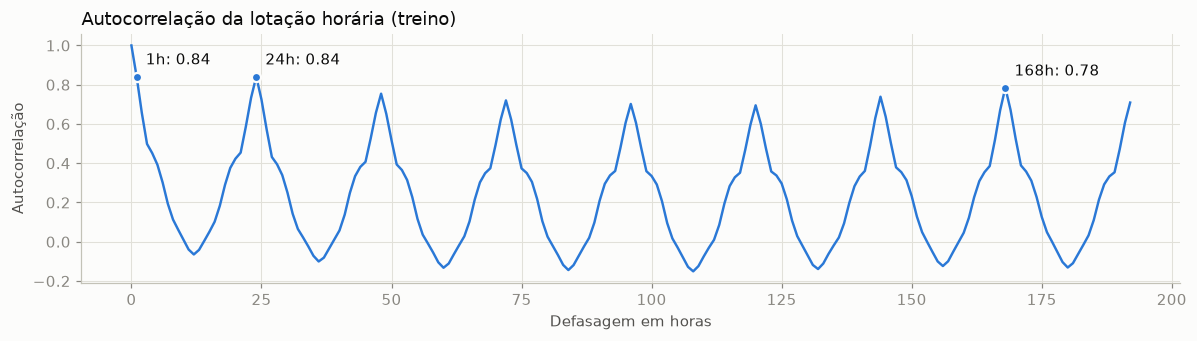

In [18]:
autocorrelation = acf(training_hourly["people_observed"], nlags=192, missing="conservative", fft=False)
highlighted_lags = {1: "1h", 24: "24h", 168: "168h"}

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(range(len(autocorrelation)), autocorrelation, color=BLUE, linewidth=1.6)
for lag, label in highlighted_lags.items():
    ax.scatter(lag, autocorrelation[lag], color=BLUE, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.annotate(f"{label}: {autocorrelation[lag]:.2f}", (lag, autocorrelation[lag]), xytext=(6, 8), textcoords="offset points", color=INK)
ax.set_title("Autocorrelação da lotação horária (treino)")
ax.set_xlabel("Defasagem em horas")
ax.set_ylabel("Autocorrelação")
fig.tight_layout()
plt.show()

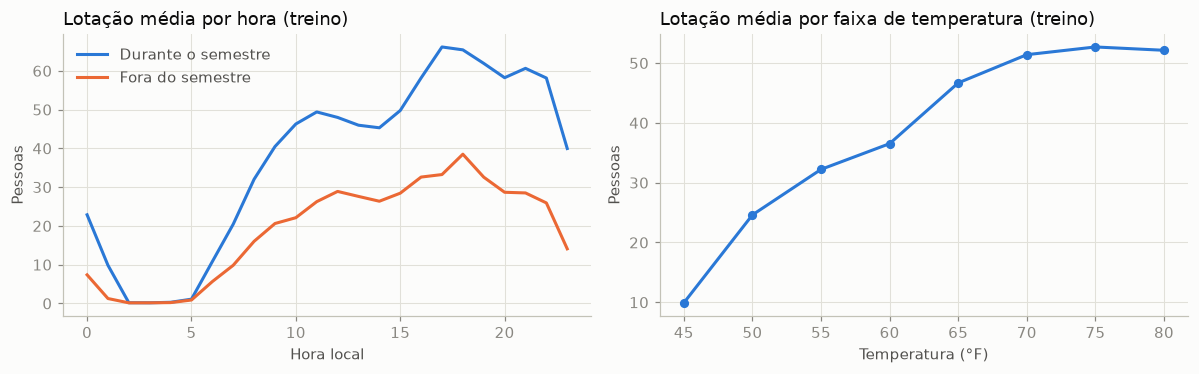

In [19]:
semester_profile = training_readings.groupby(["is_during_semester", "hour"])["number_people"].mean().unstack(level=0)
temperature_bins = training_readings["temperature"].div(5).round().mul(5)
temperature_profile = training_readings.groupby(temperature_bins)["number_people"].agg(["mean", "size"]).query("size >= 100")

fig, (semester_axis, temperature_axis) = plt.subplots(1, 2, figsize=(11, 3.5))
semester_axis.plot(semester_profile.index, semester_profile[1], color=BLUE, linewidth=2, label="Durante o semestre")
semester_axis.plot(semester_profile.index, semester_profile[0], color=ORANGE, linewidth=2, label="Fora do semestre")
semester_axis.set_title("Lotação média por hora (treino)")
semester_axis.set_xlabel("Hora local")
semester_axis.set_ylabel("Pessoas")
semester_axis.legend(loc="upper left")
temperature_axis.plot(temperature_profile.index, temperature_profile["mean"], color=BLUE, linewidth=2, marker="o", markersize=5)
temperature_axis.set_title("Lotação média por faixa de temperatura (treino)")
temperature_axis.set_xlabel("Temperatura (°F)")
temperature_axis.set_ylabel("Pessoas")
fig.tight_layout()
plt.show()

**O que os gráficos mostram**

- **Ciclo diário:** a academia fica quase vazia entre 2h e 5h, enche ao longo do dia e atinge o pico por volta das 17h e 18h nos dias úteis.
- **Ciclo semanal:** sábados e domingos têm movimento menor e começam mais tarde. Na sexta e no sábado, o movimento cai mais cedo à noite.
- **Autocorrelação:** ela vale 0,84 na defasagem de 1 hora, 0,84 em 24 horas e 0,78 em 168 horas. Esses picos justificam as janelas de 24 e 168 horas e as referências sazonais.
- **Semestre:** no horário de pico, a média é de cerca de 66 pessoas durante o semestre e 38 fora dele.
- **Temperatura:** a lotação sobe de cerca de 10 pessoas a 45 °F para mais de 50 a partir de 70 °F. Essa relação não indica causa, porque a temperatura também acompanha a hora do dia e a estação do ano.

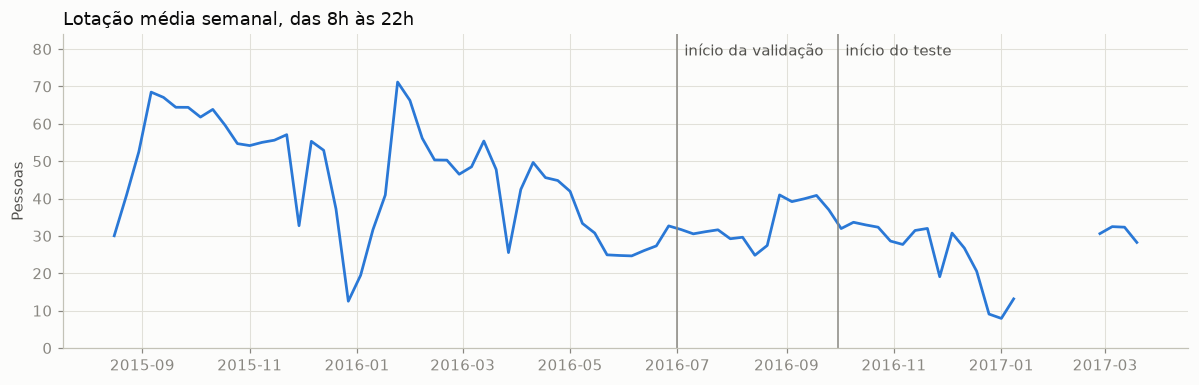

,mês,média_2015,média_2016,razão_2016_2015
0,9,65.63,38.04,0.58
1,10,58.97,31.46,0.53
2,11,49.92,27.79,0.56


,partição,média,mediana,desvio_padrão
0,treino,36.18,36.60,24.68
1,validação,22.91,24.67,16.48
2,teste,17.00,18.00,14.61


In [20]:
semester_daytime = readings[readings["hour"].between(8, 22) & readings["is_during_semester"].eq(1)]


def mean_people_in_month(year, month):
    is_selected = semester_daytime["local_time"].dt.year.eq(year) & semester_daytime["month"].eq(month)
    return semester_daytime.loc[is_selected, "number_people"].mean()


year_over_year = pd.DataFrame([
    {"mês": month, "média_2015": mean_people_in_month(2015, month), "média_2016": mean_people_in_month(2016, month)}
    for month in [9, 10, 11]
])
year_over_year["razão_2016_2015"] = year_over_year["média_2016"] / year_over_year["média_2015"]

partition_levels = pd.DataFrame([
    {
        "partição": name,
        "média": hourly.loc[dates, "people_observed"].mean(),
        "mediana": hourly.loc[dates, "people_observed"].median(),
        "desvio_padrão": hourly.loc[dates, "people_observed"].std(),
    }
    for name, dates in partitions.items()
])

weekly_daytime = readings[readings["hour"].between(8, 22)].set_index("local_time")["number_people"].resample("W").mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(weekly_daytime.index, weekly_daytime.values, color=BLUE, linewidth=1.8)
ax.set_ylim(0, weekly_daytime.max() * 1.18)
for label, boundary in [("início da validação", partitions["validação"].min()), ("início do teste", partitions["teste"].min())]:
    ax.axvline(boundary, color=MUTED_INK, linewidth=1)
    ax.annotate(label, (boundary, weekly_daytime.max() * 1.1), xytext=(5, 0), textcoords="offset points", color=SECONDARY_INK)
ax.set_title("Lotação média semanal, das 8h às 22h")
ax.set_ylabel("Pessoas")
fig.tight_layout()
plt.show()

display(year_over_year)
display(partition_levels)

**O nível da série muda ao longo do tempo.** Nos mesmos meses letivos, a lotação de 2016 ficou entre 53% e 58% da lotação de 2015. A média das datas-alvo cai de 36,18 pessoas no treino para 22,91 na validação e 17,00 no teste.

A queda aparece por volta de maio de 2016, mesmo período em que as paradas noturnas de coleta deixam de ocorrer. O dataset não informa a causa, então não é possível dizer se houve mudança real de público ou mudança na forma de medir.

O risco é o modelo aprender um nível mais alto do que o encontrado nos dados futuros. Esse efeito é medido pelo viés das previsões na seção 7.

## 5. Janelas e checagens contra vazamento

Cada exemplo usa as horas anteriores à data-alvo para prever a lotação observada naquela hora, com avanço de uma hora por vez. As janelas têm 24 horas, um ciclo diário completo, e 168 horas, um ciclo semanal completo.

Cada passo da janela tem seis entradas: a lotação padronizada, o indicador de hora preenchida, e o seno e o cosseno da hora do dia e do dia da semana. O padronizador é ajustado apenas com as observações do período de treino.

In [21]:
FEATURE_NAMES = ["people", "is_imputed", "hour_sin", "hour_cos", "weekday_sin", "weekday_cos"]

scaler = StandardScaler().fit(hourly.loc[:training_end, "people_observed"].dropna().to_numpy().reshape(-1, 1))


def build_feature_matrix(frame):
    hour_angle = 2 * np.pi * frame.index.hour.to_numpy() / 24
    weekday_angle = 2 * np.pi * frame.index.day_of_week.to_numpy() / 7
    return np.column_stack([
        scaler.transform(frame["people"].to_numpy().reshape(-1, 1)).ravel(),
        frame["is_imputed"].to_numpy(),
        np.sin(hour_angle),
        np.cos(hour_angle),
        np.sin(weekday_angle),
        np.cos(weekday_angle),
    ])


def build_examples(frame, dates, window):
    features = build_feature_matrix(frame)
    scaled_targets = scaler.transform(frame["people_observed"].to_numpy().reshape(-1, 1)).ravel()
    positions = frame.index.get_indexer(dates)
    inputs = np.stack([features[position - window : position] for position in positions])
    return inputs.astype(np.float32), scaled_targets[positions].astype(np.float32)


examples = {
    window: {name: build_examples(hourly, partitions[name], window) for name in ["treino", "validação"]}
    for window in WINDOW_LENGTHS
}

pd.DataFrame([
    {"janela_horas": window, "partição": name, "formato_entradas": str(inputs.shape), "formato_alvos": str(targets.shape)}
    for window, parts in examples.items()
    for name, (inputs, targets) in parts.items()
])

,janela_horas,partição,formato_entradas,formato_alvos
0,24,treino,"(5981, 24, 6)","(5981,)"
1,24,validação,"(1994, 24, 6)","(1994,)"
2,168,treino,"(5981, 168, 6)","(5981,)"
3,168,validação,"(1994, 168, 6)","(1994,)"


In [22]:
probe_date = pd.DatetimeIndex([partitions["validação"][0]])
probe_frame = hourly.copy()
probe_frame.loc[probe_date, ["people_observed", "people"]] += 50
original_input, original_target = build_examples(hourly, probe_date, 168)
changed_input, changed_target = build_examples(probe_frame, probe_date, 168)

observations_before_training_end = hourly.loc[:training_end, "people_observed"].dropna()

leakage_checks = {
    "Partições em ordem cronológica e sem sobreposição": (
        partitions["treino"].max() < partitions["validação"].min()
        and partitions["validação"].max() < partitions["teste"].min()
    ),
    "Teste com pelo menos 20% das datas-alvo": len(partitions["teste"]) / target_count >= 0.2,
    "Todas as datas-alvo são valores realmente observados": hourly.loc[target_hours, "people_observed"].notna().all(),
    "Janelas de 24h e 168h com o mesmo número de alvos por partição": all(
        len(examples[24][name][1]) == len(examples[168][name][1]) for name in ["treino", "validação"]
    ),
    "Janelas de 24h e 168h com os mesmos alvos": all(
        np.array_equal(examples[24][name][1], examples[168][name][1]) for name in ["treino", "validação"]
    ),
    "Nenhuma entrada vazia nas janelas": all(
        np.isfinite(inputs).all() for parts in examples.values() for inputs, _ in parts.values()
    ),
    "Alterar o alvo não muda as entradas": np.array_equal(original_input, changed_input),
    "Alterar o alvo muda o valor previsto como alvo": not np.array_equal(original_target, changed_target),
    "Padronizador ajustado só com as observações de treino": (
        scaler.n_samples_seen_ == len(observations_before_training_end)
        and np.isclose(scaler.mean_[0], observations_before_training_end.mean())
    ),
}
assert all(leakage_checks.values())

pd.Series(leakage_checks, name="passou").to_frame()

,passou
Partições em ordem cronológica e sem sobreposição,True
Teste com pelo menos 20% das datas-alvo,True
Todas as datas-alvo são valores realmente observados,True
Janelas de 24h e 168h com o mesmo número de alvos por partição,True
Janelas de 24h e 168h com os mesmos alvos,True
Nenhuma entrada vazia nas janelas,True
Alterar o alvo não muda as entradas,True
Alterar o alvo muda o valor previsto como alvo,True
Padronizador ajustado só com as observações de treino,True


## 6. Referências na validação

Antes de treinar a LSTM, medimos três previsões simples nas mesmas datas da validação. A persistência repete o último valor conhecido, e as referências sazonais repetem o valor de 24 horas ou de 168 horas antes.

In [23]:
validation_hours = partitions["validação"]
validation_actual = hourly.loc[validation_hours, "people_observed"].to_numpy()

baseline_predictions = {
    "Persistência (t-1h)": hourly["people"].shift(1).loc[validation_hours].to_numpy(),
    "Sazonal diária (t-24h)": hourly["people"].shift(24).loc[validation_hours].to_numpy(),
    "Sazonal semanal (t-168h)": hourly["people"].shift(168).loc[validation_hours].to_numpy(),
}
assert all(np.isfinite(values).all() for values in baseline_predictions.values())

baseline_results = pd.DataFrame([
    {
        "método": name,
        "MAE": np.abs(values - validation_actual).mean(),
        "viés": (values - validation_actual).mean(),
    }
    for name, values in baseline_predictions.items()
])
baseline_results

,método,MAE,viés
0,Persistência (t-1h),5.03,0.02
1,Sazonal diária (t-24h),5.27,-0.08
2,Sazonal semanal (t-168h),4.91,-0.01


## 7. Treino básico da LSTM

Este treino testa o pipeline e fornece uma primeira referência de erro. As duas janelas usam a mesma arquitetura e os mesmos hiperparâmetros: uma camada LSTM de 64 unidades, saída densa, otimizador Adam com taxa de aprendizado de 0,001, perda L1, lotes de 64 exemplos, até 30 épocas e parada antecipada com paciência de 5 épocas. Cada janela é treinada com três sementes, para separar diferenças reais de variações aleatórias.

In [24]:
class CrowdingLSTM(nn.Module):
    def __init__(self, feature_count):
        super().__init__()
        self.lstm = nn.LSTM(feature_count, HIDDEN_UNITS, batch_first=True)
        self.output = nn.Linear(HIDDEN_UNITS, 1)

    def forward(self, inputs):
        sequence_output, _ = self.lstm(inputs)
        return self.output(sequence_output[:, -1]).squeeze(-1)


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def to_people(scaled_values):
    return scaler.inverse_transform(np.asarray(scaled_values).reshape(-1, 1)).ravel()


def predict_people(model, inputs, batch_size=512):
    model.eval()
    with torch.no_grad():
        batches = [model(torch.from_numpy(inputs[start : start + batch_size])) for start in range(0, len(inputs), batch_size)]
    return to_people(torch.cat(batches).numpy())


def train_lstm(window, seed):
    set_global_seed(seed)
    train_inputs, train_targets = examples[window]["treino"]
    validation_inputs, validation_targets = examples[window]["validação"]
    validation_people = to_people(validation_targets)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_inputs), torch.from_numpy(train_targets)),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    model = CrowdingLSTM(len(FEATURE_NAMES))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.L1Loss()
    history = []
    best_mae = np.inf
    best_state = None
    epochs_without_improvement = 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        accumulated_loss = 0.0
        for batch_inputs, batch_targets in loader:
            optimizer.zero_grad()
            loss = loss_function(model(batch_inputs), batch_targets)
            loss.backward()
            optimizer.step()
            accumulated_loss += loss.item() * len(batch_targets)
        train_mae = accumulated_loss / len(train_targets) * scaler.scale_[0]
        validation_mae = np.abs(predict_people(model, validation_inputs) - validation_people).mean()
        history.append({"época": epoch, "treino": train_mae, "validação": validation_mae})
        if validation_mae < best_mae:
            best_mae = validation_mae
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            break
    model.load_state_dict(best_state)
    predictions = predict_people(model, validation_inputs)
    return {
        "janela": window,
        "semente": seed,
        "melhor_época": int(pd.DataFrame(history)["validação"].idxmin()) + 1,
        "épocas_treinadas": len(history),
        "MAE": np.abs(predictions - validation_people).mean(),
        "viés": (predictions - validation_people).mean(),
        "history": pd.DataFrame(history),
        "predictions": predictions,
    }


training_runs = [train_lstm(window, seed) for window in WINDOW_LENGTHS for seed in SEEDS]
run_table = pd.DataFrame([{key: run[key] for key in ["janela", "semente", "melhor_época", "épocas_treinadas", "MAE", "viés"]} for run in training_runs])
run_table

,janela,semente,melhor_época,épocas_treinadas,MAE,viés
0,24,7,8,13,3.66,-0.36
1,24,21,25,30,3.24,0.14
2,24,42,29,30,3.22,0.66
3,168,7,30,30,3.18,0.35
4,168,21,22,27,3.30,-0.37
5,168,42,29,30,3.25,0.02


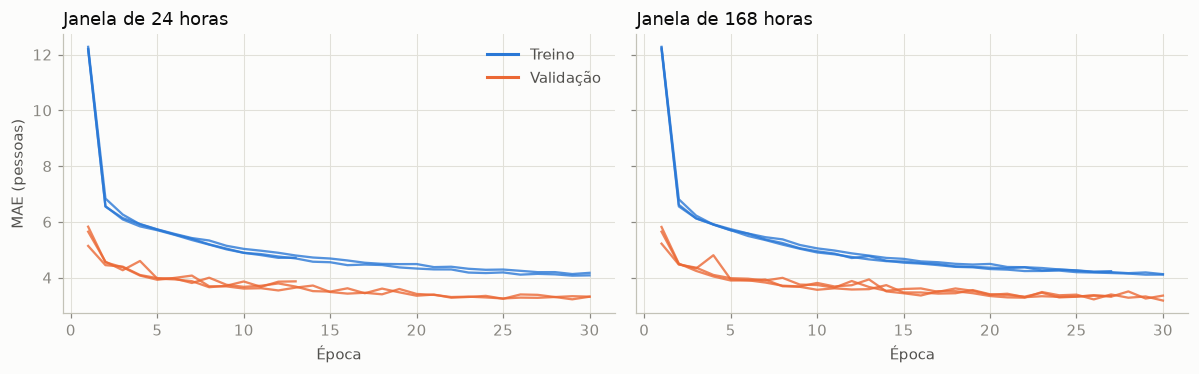

In [25]:
fig, axes = plt.subplots(1, len(WINDOW_LENGTHS), figsize=(11, 3.5), sharey=True)
for ax, window in zip(axes, WINDOW_LENGTHS):
    for run in [run for run in training_runs if run["janela"] == window]:
        ax.plot(run["history"]["época"], run["history"]["treino"], color=BLUE, linewidth=1.5, alpha=0.8)
        ax.plot(run["history"]["época"], run["history"]["validação"], color=ORANGE, linewidth=1.5, alpha=0.8)
    ax.set_title(f"Janela de {window} horas")
    ax.set_xlabel("Época")
axes[0].set_ylabel("MAE (pessoas)")
axes[0].plot([], [], color=BLUE, linewidth=2, label="Treino")
axes[0].plot([], [], color=ORANGE, linewidth=2, label="Validação")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

In [26]:
window_summary = run_table.groupby("janela").agg(MAE_médio=("MAE", "mean"), desvio_entre_sementes=("MAE", "std"), viés_médio=("viés", "mean"))
selected_window = int(window_summary["MAE_médio"].idxmin())
persistence_mae = baseline_results.set_index("método").loc["Persistência (t-1h)", "MAE"]

comparison_rows = [
    {
        "método": f"LSTM, janela de {window}h" + (" (melhor janela)" if window == selected_window else ""),
        "MAE": row["MAE_médio"],
        "desvio_entre_sementes": row["desvio_entre_sementes"],
        "viés": row["viés_médio"],
    }
    for window, row in window_summary.iterrows()
] + [
    {"método": row["método"], "MAE": row["MAE"], "desvio_entre_sementes": np.nan, "viés": row["viés"]}
    for _, row in baseline_results.iterrows()
]
validation_comparison = pd.DataFrame(comparison_rows).sort_values("MAE").reset_index(drop=True)
validation_comparison["diferença_para_persistência_%"] = 100 * (validation_comparison["MAE"] / persistence_mae - 1)
validation_comparison

,método,MAE,desvio_entre_sementes,viés,diferença_para_persistência_%
0,"LSTM, janela de 168h (melhor janela)",3.24,0.06,-0.00,-35.51
1,"LSTM, janela de 24h",3.37,0.25,0.15,-32.91
2,Sazonal semanal (t-168h),4.91,NaN,-0.01,-2.30
3,Persistência (t-1h),5.03,NaN,0.02,0.00
4,Sazonal diária (t-24h),5.27,NaN,-0.08,4.93


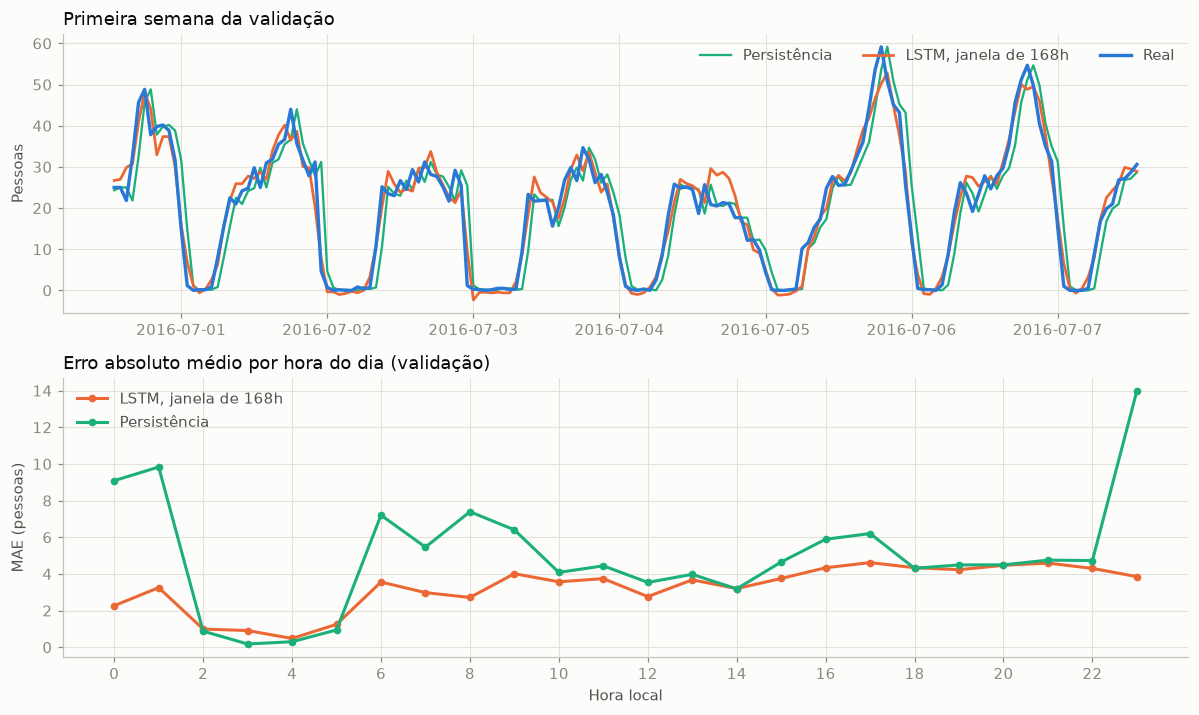

In [27]:
selected_runs = sorted([run for run in training_runs if run["janela"] == selected_window], key=lambda run: run["MAE"])
median_run = selected_runs[len(selected_runs) // 2]

validation_frame = pd.DataFrame(
    {
        "real": validation_actual,
        "lstm": median_run["predictions"],
        "persistência": baseline_predictions["Persistência (t-1h)"],
    },
    index=validation_hours,
)
first_week = validation_frame.loc[validation_hours[0] : validation_hours[0] + pd.Timedelta(days=7)].asfreq("1h")
error_by_hour = validation_frame.assign(
    hour_of_day=validation_frame.index.hour,
    lstm_error=(validation_frame["lstm"] - validation_frame["real"]).abs(),
    persistence_error=(validation_frame["persistência"] - validation_frame["real"]).abs(),
).groupby("hour_of_day")[["lstm_error", "persistence_error"]].mean()

fig, (series_axis, error_axis) = plt.subplots(2, 1, figsize=(11, 6.6))
series_axis.plot(first_week.index, first_week["persistência"], color=AQUA, linewidth=1.5, label="Persistência")
series_axis.plot(first_week.index, first_week["lstm"], color=ORANGE, linewidth=1.8, label=f"LSTM, janela de {selected_window}h")
series_axis.plot(first_week.index, first_week["real"], color=BLUE, linewidth=2.2, label="Real")
series_axis.set_title("Primeira semana da validação")
series_axis.set_ylabel("Pessoas")
series_axis.legend(loc="upper right", ncols=3)
error_axis.plot(error_by_hour.index, error_by_hour["lstm_error"], color=ORANGE, linewidth=2, marker="o", markersize=4, label=f"LSTM, janela de {selected_window}h")
error_axis.plot(error_by_hour.index, error_by_hour["persistence_error"], color=AQUA, linewidth=2, marker="o", markersize=4, label="Persistência")
error_axis.set_title("Erro absoluto médio por hora do dia (validação)")
error_axis.set_xlabel("Hora local")
error_axis.set_ylabel("MAE (pessoas)")
error_axis.set_xticks(range(0, 24, 2))
error_axis.legend(loc="upper left")
fig.tight_layout()
plt.show()

**O que o primeiro treino mostra**

- **Janela:** a janela de 168 horas teve o menor MAE médio, 3,24 pessoas, contra 3,37 da janela de 24 horas. A diferença de 0,13 é menor que o desvio entre sementes da janela de 24 horas (0,25), então este treino ainda não prova que o histórico mais longo ajuda. Duas das três sementes de 24 horas chegaram a 3,24 e 3,22, resultados equivalentes aos da janela de 168 horas.
- **Referências:** as duas LSTMs erraram menos que todas as referências. A melhor referência foi a sazonal semanal, com MAE de 4,91, e a persistência teve 5,03. A LSTM de 168 horas ficou 35,51% abaixo da persistência.
- **Viés:** o viés médio ficou próximo de zero (0,00 na janela de 168 horas e 0,15 na de 24 horas). Mesmo treinado em um período de nível mais alto, o modelo não superestimou a validação de forma sistemática.
- **Onde a LSTM ganha:** a persistência erra muito no fechamento e na abertura, com MAE de 14,0 às 23h. A LSTM aprende esses horários e mantém o erro abaixo de 5 pessoas em todas as horas do dia. Entre 2h e 5h, a persistência é ligeiramente melhor, porque a lotação fica perto de zero.

**Limitações deste resultado**

- A parada antecipada usa a própria validação, então o MAE da LSTM está um pouco otimista em relação ao das referências.
- Quatro dos seis treinos chegaram ao limite de 30 épocas, e cinco tiveram a melhor época a partir da 22ª. O modelo provavelmente ainda não convergiu por completo.
- A LSTM produz previsões levemente negativas de madrugada, o que não faz sentido para uma contagem de pessoas.
- O erro de treino fica acima do erro de validação porque o período de treino tem lotação mais alta, e não por um problema no treinamento.

## 8. Conclusões

### Problemas encontrados e tratamentos

| Problema | Evidência no notebook | Tratamento | Por que este tratamento |
|---|---|---|---|
| Leituras fora de ordem | 1 inversão, na troca de horário de 06/11/2016 | Ordenação pelo instante em UTC | O UTC não repete horas na mudança de horário |
| Amostragem irregular | Mediana de 10 min, com 8,73% dos intervalos acima de 15 min | Média em grade de 1 hora | Reduz as posições vazias de 26,28% para 16,71% e faz cada janela representar um ciclo exato |
| Lacunas noturnas | 252 das 308 lacunas acima de 3h começam à 1h, com duração mediana de 4,3h | Preenchimento de até 8h, marcado em `is_imputed` | Os alvos com janela semanal completa sobem de 3.852 para 9.969, com 8,03% das horas preenchidas |
| Vazamento pela interpolação | Somar 50 pessoas ao alvo altera a entrada em até 37,5 pessoas | Repetição do último valor observado | A entrada deixa de depender do alvo, e a diferença no teste cai a zero |
| Lacunas longas | 16 lacunas acima de 8h; as maiores têm 25,0, 10,9 e 8,5 dias | Horas mantidas vazias e janelas afetadas descartadas | Evita inventar dias ou semanas de dados |
| Teste reduzido pelo calendário | O corte por calendário deixa o teste com 46,40% de horas vazias e 12,87% das observações | Divisão 60/20/20 pelas datas-alvo elegíveis | O teste fica com 1.994 datas-alvo, 20% do total |
| Mudança de nível | 2016 ficou entre 53% e 58% de 2015 nos mesmos meses | Monitoramento do viés na validação | A causa é desconhecida, e o viés medido ficou próximo de zero |

### O dataset serve para o trabalho?

**Sim.** A série tem ciclos diário e semanal claros, volume suficiente depois da limpeza (9.969 datas-alvo) e todas as checagens contra vazamento passaram. O pipeline funcionou de ponta a ponta, e a LSTM básica superou as três referências na validação.

### Riscos para a etapa final

- A média das datas-alvo no teste é de 17,00 pessoas, abaixo das 22,91 da validação, e o período inclui o recesso de fim de ano. O bom resultado na validação não garante o mesmo desempenho no teste.
- O trecho final tem as maiores lacunas, e os últimos 15 dias da série ficam fora das datas-alvo porque não têm janela semanal completa.
- A vantagem da janela de 168 horas ainda está dentro da variação entre sementes.

### Próximos passos

1. Aumentar o limite de épocas e o número de sementes, para comparar as janelas com mais segurança.
2. Limitar as previsões a valores não negativos.
3. Avaliar se temperatura e período letivo melhoram o modelo, usando apenas a validação.
4. Executar a avaliação final no teste uma única vez, com a janela escolhida, a persistência e a referência sazonal.

### Perguntas para a professora

1. A previsão da próxima hora, em grade horária, atende ao objetivo do trabalho?
2. É aceitável que os últimos 15 dias da série fiquem fora do teste por falta de janela semanal completa?
3. O preenchimento de lacunas de até 8 horas com o último valor observado é adequado?
4. Devemos manter todo o histórico no treino, mesmo com a mudança de nível em 2016, ou comparar com um treino restrito ao período mais recente?